# EDA · Relaciones entre variables y selección de features · World Happiness 2015-2019

**Workshop-3 · ETL (G01)** — Paso 3 del taller (feature engineering): estadísticas descriptivas, visualizaciones y pruebas estadísticas para decidir qué variables usa el modelo.

Parte del dataset ya limpio y unificado (`data/processed/happiness_unified.csv`, generado por `python -m happiness_etl.main`). La calidad de los datos crudos se revisó antes en `profiling.ipynb`.

**Regla para evitar fugas de información:** el dataset se divide primero en entrenamiento (70 %) y prueba (30 %). Todo el análisis y todas las decisiones se toman **solo con el entrenamiento**; el conjunto de prueba no se mira aquí y se usa una sola vez, al final, en `model_training.ipynb`.

## 0. Configuración

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split

from happiness_etl.config import COUNTRY, FEATURES, RANDOM_STATE, TARGET, TEST_SIZE, YEAR, YEARS
from happiness_etl.load import read_processed

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)
pd.set_option("display.precision", 3)
sns.set_theme(style="whitegrid")
FEATURES = list(FEATURES)

## 1. Carga y división entrenamiento / prueba
La división se estratifica por año para que cada año tenga la misma proporción en ambos conjuntos
(los años tienen escalas distintas, así que conviene que el entrenamiento los represente a todos por igual).

In [2]:
datos = read_processed()
train, test = train_test_split(datos, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=datos[YEAR])
train = train.reset_index(drop=True)

pd.DataFrame({
    "total": datos[YEAR].value_counts().sort_index(),
    "train": train[YEAR].value_counts().sort_index(),
    "test": test[YEAR].value_counts().sort_index(),
}).assign(pct_train=lambda d: (d["train"] / d["total"]).round(3))

,total,train,test,pct_train
year,,,,
2015,158,111,47,0.703
2016,157,110,47,0.701
2017,155,108,47,0.697
2018,156,109,47,0.699
2019,156,109,47,0.699


## 2. Variable objetivo: `happiness_score`
### 2.1 Distribución

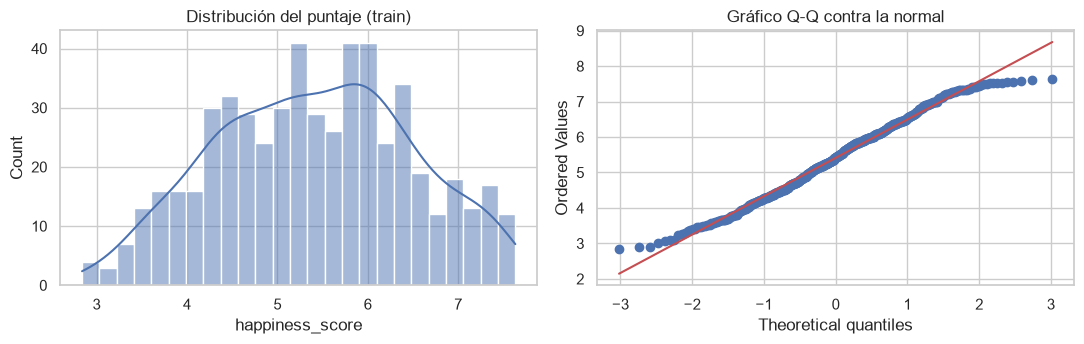

,valor
n,5.470e+02
media,5.412e+00
mediana,5.425e+00
desv,1.083e+00
asimetria,-3.290e-02
curtosis_exceso,-7.051e-01
shapiro_W,9.877e-01
shapiro_p,1.000e-04


In [3]:
y = train[TARGET]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
sns.histplot(y, bins=25, kde=True, ax=axes[0], color="#4c72b0")
axes[0].set_title("Distribución del puntaje (train)")
stats.probplot(y, dist="norm", plot=axes[1])
axes[1].set_title("Gráfico Q-Q contra la normal")
plt.tight_layout()
plt.show()

shapiro = stats.shapiro(y)
pd.Series({
    "n": len(y), "media": y.mean(), "mediana": y.median(), "desv": y.std(),
    "asimetria": stats.skew(y), "curtosis_exceso": stats.kurtosis(y),
    "shapiro_W": shapiro.statistic, "shapiro_p": shapiro.pvalue,
}).round(4).to_frame("valor")

### 2.2 ¿El puntaje cambia entre años?
Si el puntaje es estable entre años pero las variables explicativas cambian de escala, el año podría ayudar al modelo a corregir esa diferencia.
Se usa ANOVA de una vía y, como respaldo no paramétrico, Kruskal-Wallis.

In [4]:
grupos = [g[TARGET].to_numpy() for _, g in train.groupby(YEAR)]
anova = stats.f_oneway(*grupos)
kruskal = stats.kruskal(*grupos)
levene = stats.levene(*grupos)
pd.DataFrame({
    "estadistico": [anova.statistic, kruskal.statistic, levene.statistic],
    "p_valor": [anova.pvalue, kruskal.pvalue, levene.pvalue],
}, index=["ANOVA (medias)", "Kruskal-Wallis (distribuciones)", "Levene (varianzas)"])

,estadistico,p_valor
ANOVA (medias),0.589,0.671
Kruskal-Wallis (distribuciones),2.271,0.686
Levene (varianzas),0.297,0.880


In [5]:
train.groupby(YEAR)[TARGET].agg(["count", "mean", "median", "std"])

,count,mean,median,std
year,,,,
2015,111,5.423,5.429,1.110
2016,110,5.429,5.421,1.135
2017,108,5.530,5.590,1.068
2018,109,5.319,5.347,1.085
2019,109,5.362,5.373,1.022


## 3. Variables explicativas
### 3.1 Distribuciones por año
El profiling mostró que `family` y `health` cambian de escala entre reportes. Aquí se mide con pruebas.

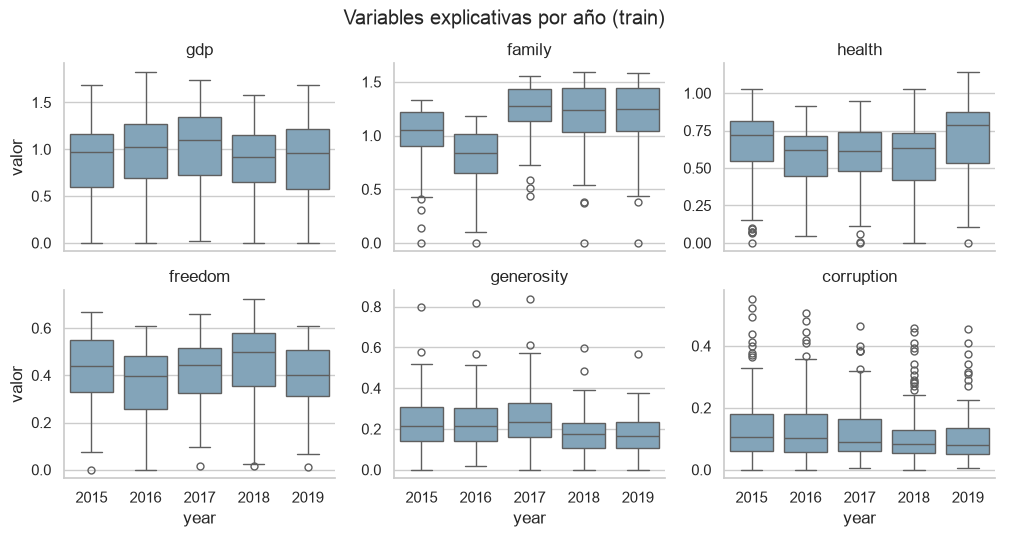

In [6]:
largo = train.melt(id_vars=[YEAR], value_vars=FEATURES, var_name="variable", value_name="valor")
g = sns.catplot(data=largo, x=YEAR, y="valor", col="variable", col_wrap=3, kind="box",
                sharey=False, height=2.6, aspect=1.3, color="#7aa6c2")
g.set_titles("{col_name}")
g.figure.suptitle("Variables explicativas por año (train)", y=1.03)
plt.show()

### 3.2 ¿Las variables cambian entre años? (Kruskal-Wallis + tamaño del efecto)
Con varios cientos de filas casi cualquier diferencia sale "significativa", así que además del p-valor se reporta
el tamaño del efecto **ε²** (épsilon cuadrado de Kruskal-Wallis): ~0.01 pequeño, ~0.06 mediano, ≥0.14 grande.

In [7]:
def kruskal_por_anio(df, columna):
    grupos = [g[columna].to_numpy() for _, g in df.groupby(YEAR)]
    h, p = stats.kruskal(*grupos)
    n, k = len(df), len(grupos)
    epsilon2 = (h - k + 1) / (n - k)  # tamaño del efecto (Tomczak & Tomczak, 2014)
    return {"H": h, "p_valor": p, "epsilon2": epsilon2}


escala = pd.DataFrame({col: kruskal_por_anio(train, col) for col in [*FEATURES, TARGET]}).T
escala["efecto"] = pd.cut(escala["epsilon2"], [-np.inf, 0.01, 0.06, 0.14, np.inf],
                          labels=["despreciable", "pequeño", "mediano", "grande"])
escala.join(train.groupby(YEAR)[[*FEATURES, TARGET]].mean().T.add_prefix("media_"))

,H,p_valor,epsilon2,efecto,media_2015,media_2016,media_2017,media_2018,media_2019
gdp,12.184,1.604e-02,0.015,pequeño,0.874,0.960,1.019,0.875,0.896
family,162.996,3.329e-34,0.293,grande,1.001,0.800,1.243,1.191,1.200
health,34.131,7.006e-07,0.056,pequeño,0.649,0.569,0.581,0.577,0.712
freedom,23.886,8.417e-05,0.037,pequeño,0.431,0.369,0.419,0.452,0.392
generosity,36.288,2.525e-07,0.060,pequeño,0.232,0.237,0.254,0.180,0.172
corruption,8.780,6.684e-02,0.009,despreciable,0.138,0.135,0.126,0.112,0.101
happiness_score,2.271,6.860e-01,-0.003,despreciable,5.423,5.429,5.530,5.319,5.362


### 3.3 ¿Es un cambio real de los países o un cambio de metodología?
Si fuera un cambio real, los países evolucionarían de forma gradual. Si es un cambio de metodología del reporte,
**el mismo país** salta de golpe entre dos años consecutivos. Se compara cada país consigo mismo entre años
consecutivos (prueba de rangos con signo de Wilcoxon, pareada por país) y se reporta la mediana del cambio.

In [8]:
def cambios_pareados(df, columna):
    ancho = df.pivot_table(index=COUNTRY, columns=YEAR, values=columna)
    filas = []
    for a, b in zip(YEARS[:-1], YEARS[1:]):
        pares = ancho[[a, b]].dropna()
        diff = pares[b] - pares[a]
        w = stats.wilcoxon(pares[b], pares[a])
        filas.append({"variable": columna, "tramo": f"{a}→{b}", "paises": len(pares),
                      "mediana_cambio": diff.median(), "pct_suben": (diff > 0).mean(), "p_valor": w.pvalue})
    return filas


# Para comparar el mismo país en dos años se necesitan ambos años: se usa el dataset completo solo
# con las variables explicativas (no se mira el puntaje), así que no hay fuga del target.
pareado = pd.DataFrame([f for col in FEATURES for f in cambios_pareados(datos, col)])
pareado.pivot_table(index="variable", columns="tramo", values="mediana_cambio").round(3)

tramo,2015→2016,2016→2017,2017→2018,2018→2019
variable,,,,
corruption,-0.006,-0.010,-0.007,-0.004
family,-0.195,0.399,0.032,-0.004
freedom,-0.068,0.039,0.050,-0.074
gdp,0.104,0.038,-0.104,0.027
generosity,0.002,0.004,-0.055,0.004
health,-0.085,-0.001,0.046,0.131


In [9]:
pareado.pivot_table(index="variable", columns="tramo", values="pct_suben").round(2)

tramo,2015→2016,2016→2017,2017→2018,2018→2019
variable,,,,
corruption,0.36,0.20,0.33,0.35
family,0.00,1.00,0.75,0.45
freedom,0.07,0.91,0.89,0.08
gdp,0.99,0.98,0.03,0.92
generosity,0.53,0.58,0.04,0.56
health,0.03,0.44,0.94,0.99


## 4. Relación de cada variable con el puntaje
### 4.1 Diagramas de dispersión

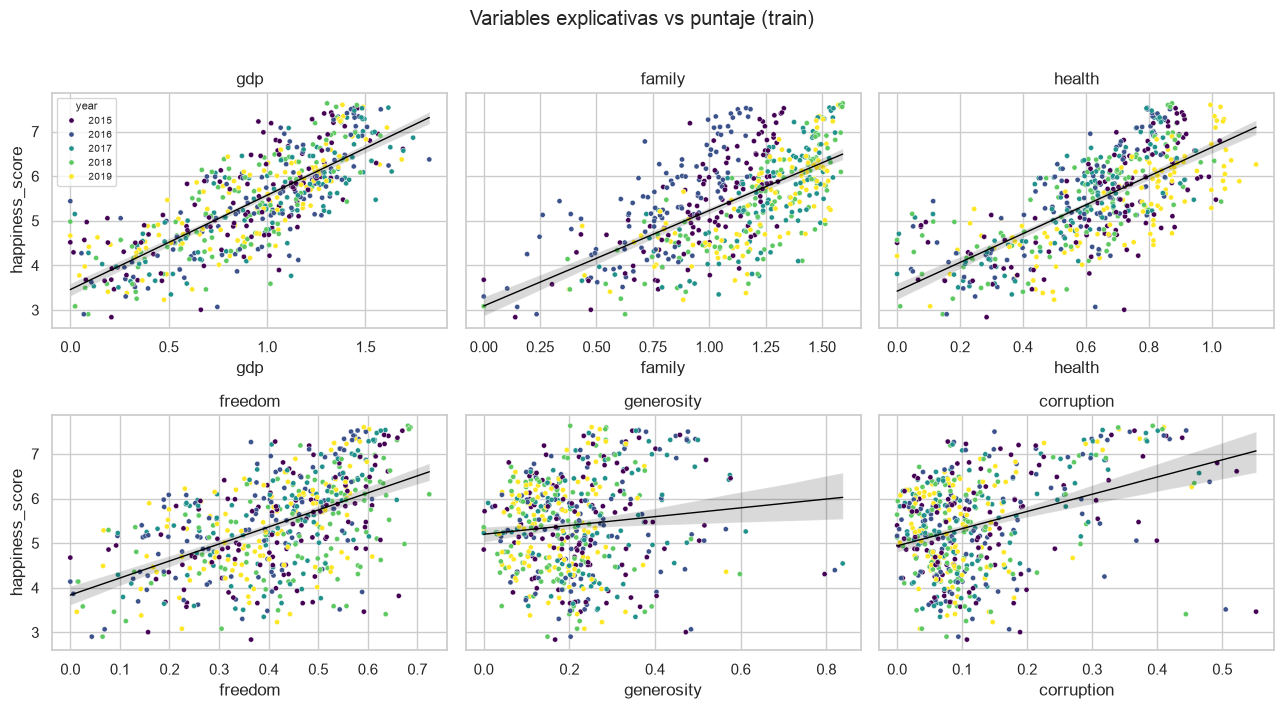

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7), sharey=True)
for ax, col in zip(axes.flat, FEATURES):
    sns.scatterplot(data=train, x=col, y=TARGET, hue=YEAR, palette="viridis", s=14, ax=ax, legend=(col == FEATURES[0]))
    sns.regplot(data=train, x=col, y=TARGET, scatter=False, color="black", line_kws={"lw": 1}, ax=ax)
    ax.set_title(col)
axes.flat[0].legend(title="year", fontsize=7, title_fontsize=8)
fig.suptitle("Variables explicativas vs puntaje (train)", y=1.01)
plt.tight_layout()
plt.show()

### 4.2 Correlaciones con intervalo de confianza
Pearson mide relación lineal; Spearman, relación monótona (robusta a outliers). El intervalo del 95 % de Pearson
se calcula con la transformación z de Fisher.

In [11]:
def correlacion(x, y):
    n = len(x)
    r, p = stats.pearsonr(x, y)
    z, se = np.arctanh(r), 1 / np.sqrt(n - 3)
    rho, p_rho = stats.spearmanr(x, y)
    return {"pearson_r": r, "ic95_inf": np.tanh(z - 1.96 * se), "ic95_sup": np.tanh(z + 1.96 * se),
            "p_pearson": p, "spearman_rho": rho, "p_spearman": p_rho}


corr = pd.DataFrame({col: correlacion(train[col], train[TARGET]) for col in FEATURES}).T
corr.sort_values("pearson_r", ascending=False)

,pearson_r,ic95_inf,ic95_sup,p_pearson,spearman_rho,p_spearman
gdp,0.781,0.746,0.812,1.874e-113,0.796,9.957e-121
health,0.715,0.671,0.754,8.930e-87,0.735,3.810e-94
family,0.634,0.581,0.682,7.034e-63,0.626,7.987e-61
freedom,0.527,0.463,0.585,2.429e-40,0.528,1.347e-40
corruption,0.370,0.295,0.440,3.638e-19,0.259,7.874e-10
generosity,0.113,0.029,0.195,8.170e-03,0.110,9.704e-03


### 4.3 ¿El cambio de escala altera la relación con el puntaje?
Se compara la correlación **dentro de cada año** con la correlación **agrupada** (todos los años juntos).
Si agrupar años con escalas distintas mezcla las relaciones, la correlación agrupada sale menor que la de cada año.
También se estima la pendiente de una regresión simple del puntaje sobre cada variable, por año.

In [12]:
por_anio = train.groupby(YEAR).apply(lambda g: g[FEATURES].corrwith(g[TARGET]), include_groups=False).T
por_anio["agrupada"] = train[FEATURES].corrwith(train[TARGET])
por_anio["media_por_anio"] = por_anio[list(YEARS)].mean(axis=1)
por_anio.round(3)

year,2015,2016,2017,2018,2019,agrupada,media_por_anio
gdp,0.755,0.776,0.801,0.783,0.808,0.781,0.784
family,0.742,0.763,0.723,0.770,0.741,0.634,0.748
health,0.689,0.743,0.781,0.747,0.766,0.715,0.745
freedom,0.522,0.581,0.556,0.525,0.525,0.527,0.542
generosity,0.037,0.165,0.178,0.047,0.042,0.113,0.094
corruption,0.319,0.344,0.500,0.337,0.365,0.370,0.373


In [13]:
pendientes = train.groupby(YEAR).apply(
    lambda g: pd.Series({col: stats.linregress(g[col], g[TARGET]).slope for col in FEATURES}),
    include_groups=False,
).T
pendientes["cv_entre_anios"] = pendientes.std(axis=1) / pendientes.mean(axis=1).abs()
pendientes.round(3)

year,2015,2016,2017,2018,2019,cv_entre_anios
gdp,2.070,2.225,2.058,2.307,2.051,0.055
family,3.123,3.317,3.193,2.724,2.513,0.114
health,3.126,3.946,3.818,3.291,3.157,0.111
freedom,3.981,4.385,4.267,3.475,3.971,0.088
generosity,0.327,1.378,1.383,0.501,0.475,0.643
corruption,3.013,3.515,5.242,3.726,4.413,0.217


### 4.4 Colinealidad entre variables explicativas
Correlación entre pares y factor de inflación de la varianza (**VIF**). Regla habitual: VIF > 5 indica colinealidad
preocupante y VIF > 10 grave. Se calcula con scikit-learn: VIF_j = 1 / (1 − R²_j), donde R²_j es el ajuste de la
variable j explicada por las demás.

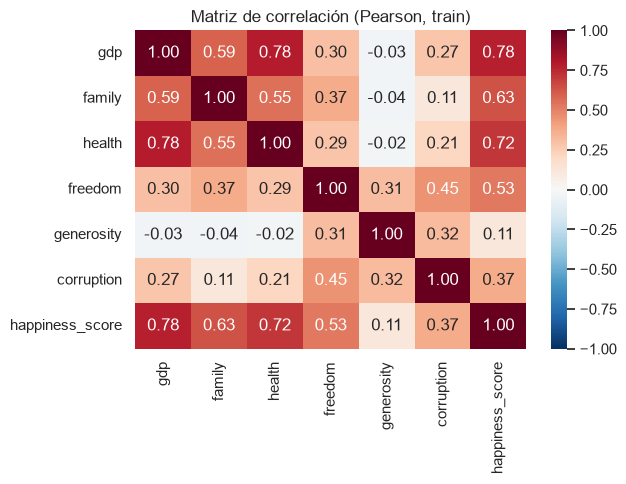

In [14]:
fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(train[[*FEATURES, TARGET]].corr(), annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax)
ax.set_title("Matriz de correlación (Pearson, train)")
plt.tight_layout()
plt.show()

In [15]:
from sklearn.linear_model import LinearRegression


def vif(df, columnas):
    salida = {}
    for col in columnas:
        otras = [c for c in columnas if c != col]
        r2 = LinearRegression().fit(df[otras], df[col]).score(df[otras], df[col])
        salida[col] = 1 / (1 - r2)
    return pd.Series(salida, name="VIF")


vif(train, FEATURES).sort_values(ascending=False).round(2)

gdp           2.98
health        2.70
family        1.74
freedom       1.53
corruption    1.40
generosity    1.20
Name: VIF, dtype: float64

## 5. Comparación de modelos candidatos (validación cruzada sobre train)
Se comparan variantes simples para responder tres preguntas con evidencia:
1. ¿Conviene que el modelo use el año para corregir el cambio de escala entre reportes?
2. ¿Aportan `generosity` y `corruption`, las dos variables más débiles?
3. ¿Un modelo no lineal (Random Forest) mejora claramente a la regresión lineal?

Formas de usar el año:
- **`+ year` (one-hot):** una columna por año; en un modelo lineal desplaza la constante de cada reporte.
- **Estandarización por año:** cada variable se estandariza con la media y desviación **de su año**, aprendidas del train.
  Así un valor se lee como "qué tan alto está el país respecto a los demás en ese mismo reporte", sin importar la escala del año.

Protocolo: validación cruzada 5 *folds* repetida 5 veces (25 ajustes por modelo, mismas particiones para todos).
Todo el preprocesamiento va dentro de un `Pipeline`, así que se aprende solo con los datos de entrenamiento de cada *fold*.

In [16]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import RepeatedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler


class YearStandardizer(BaseEstimator, TransformerMixin):
    """Estandariza cada variable con la media y desviación de su año (aprendidas en fit).

    Recibe un DataFrame con `year` y las variables; devuelve solo las variables estandarizadas.
    Un año que no se vio en fit usa la media y desviación global.
    """

    def __init__(self, columns):
        self.columns = columns

    def fit(self, X, y=None):
        cols = list(self.columns)
        self.means_ = X.groupby(YEAR)[cols].mean()
        self.stds_ = X.groupby(YEAR)[cols].std(ddof=0).replace(0, 1)
        self.global_mean_ = X[cols].mean()
        self.global_std_ = X[cols].std(ddof=0).replace(0, 1)
        return self

    def transform(self, X):
        cols = list(self.columns)
        years = X[YEAR]
        mean = self.means_.reindex(years).fillna(self.global_mean_).to_numpy()
        std = self.stds_.reindex(years).fillna(self.global_std_).to_numpy()
        return (X[cols].to_numpy() - mean) / std

    def get_feature_names_out(self, input_features=None):
        return np.array(list(self.columns))


def lineal(features, year=None):
    """Pipeline lineal: year=None (sin año), 'onehot' o 'por_anio' (estandarización por año)."""
    features = list(features)
    if year == "por_anio":
        prep = ColumnTransformer([("num", YearStandardizer(features), [YEAR, *features])])
    else:
        partes = [("num", StandardScaler(), features)]
        if year == "onehot":
            partes.append(("year", OneHotEncoder(handle_unknown="ignore", drop="first"), [YEAR]))
        prep = ColumnTransformer(partes)
    return Pipeline([("prep", prep), ("modelo", LinearRegression())])


def bosque(features, year=False):
    cols = [*features, YEAR] if year else list(features)
    prep = ColumnTransformer([("pasa", "passthrough", cols)])
    rf = RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=RANDOM_STATE, n_jobs=1)
    return Pipeline([("prep", prep), ("modelo", rf)])


sin_gen = [f for f in FEATURES if f != "generosity"]
sin_cor = [f for f in FEATURES if f != "corruption"]
sin_ambas = [f for f in FEATURES if f not in ("generosity", "corruption")]

candidatos = {
    "LR base (6 variables)": lineal(FEATURES),
    "LR + year one-hot": lineal(FEATURES, "onehot"),
    "LR estandarizada por año": lineal(FEATURES, "por_anio"),
    "LR por año sin generosity": lineal(sin_gen, "por_anio"),
    "LR por año sin corruption": lineal(sin_cor, "por_anio"),
    "LR por año sin ambas": lineal(sin_ambas, "por_anio"),
    "RF base (6 variables)": bosque(FEATURES),
    "RF + year": bosque(FEATURES, year=True),
}

In [17]:
X_train = train[[YEAR, *FEATURES]]
y_train = train[TARGET]
cv = RepeatedKFold(n_splits=5, n_repeats=5, random_state=RANDOM_STATE)
metricas = {"rmse": "neg_root_mean_squared_error", "mae": "neg_mean_absolute_error", "r2": "r2"}

resultados_cv = {}
for nombre, modelo in candidatos.items():
    r = cross_validate(modelo, X_train, y_train, cv=cv, scoring=metricas)
    resultados_cv[nombre] = pd.DataFrame({"rmse": -r["test_rmse"], "mae": -r["test_mae"], "r2": r["test_r2"]})

resumen = pd.DataFrame({
    nombre: {"RMSE": d["rmse"].mean(), "RMSE_desv": d["rmse"].std(), "MAE": d["mae"].mean(), "R2": d["r2"].mean()}
    for nombre, d in resultados_cv.items()
}).T.sort_values("RMSE")
resumen

,RMSE,RMSE_desv,MAE,R2
RF + year,0.515,0.040,0.400,0.771
RF base (6 variables),0.519,0.040,0.402,0.768
LR por año sin generosity,0.528,0.036,0.409,0.759
LR estandarizada por año,0.529,0.036,0.410,0.759
LR por año sin ambas,0.530,0.035,0.414,0.758
LR + year one-hot,0.530,0.040,0.413,0.758
LR por año sin corruption,0.530,0.035,0.414,0.758
LR base (6 variables),0.554,0.044,0.433,0.735


### 5.1 ¿Las diferencias son reales? Prueba t corregida (Nadeau y Bengio, 2003)
Los 25 resultados de validación cruzada no son independientes (los *folds* comparten datos de entrenamiento),
así que una prueba t pareada normal sale demasiado optimista. La corrección de Nadeau y Bengio infla la varianza
según la proporción test/train. Se compara el RMSE de cada modelo contra la **LR base**.

In [18]:
def t_corregida(a, b, n_train, n_test):
    """Prueba t pareada corregida para validación cruzada repetida (Nadeau & Bengio, 2003)."""
    d = np.asarray(a) - np.asarray(b)
    k = len(d)
    var = np.var(d, ddof=1)
    t = d.mean() / np.sqrt((1 / k + n_test / n_train) * var)
    p = 2 * stats.t.sf(abs(t), df=k - 1)
    return d.mean(), t, p


n_val = len(train) // 5
n_fit = len(train) - n_val
base = resultados_cv["LR base (6 variables)"]["rmse"]
comparacion = pd.DataFrame({
    nombre: dict(zip(["dif_RMSE_vs_base", "t", "p_valor"], t_corregida(d["rmse"], base, n_fit, n_val)))
    for nombre, d in resultados_cv.items() if nombre != "LR base (6 variables)"
}).T
comparacion["mejora_pct"] = -comparacion["dif_RMSE_vs_base"] / base.mean() * 100
comparacion.sort_values("dif_RMSE_vs_base")

,dif_RMSE_vs_base,t,p_valor,mejora_pct
RF + year,-0.039,-2.636,0.014,7.034
RF base (6 variables),-0.035,-2.349,0.027,6.356
LR por año sin generosity,-0.026,-2.278,0.032,4.678
LR estandarizada por año,-0.025,-2.256,0.033,4.515
LR por año sin ambas,-0.024,-1.943,0.064,4.387
LR + year one-hot,-0.024,-2.439,0.023,4.376
LR por año sin corruption,-0.024,-1.977,0.060,4.311


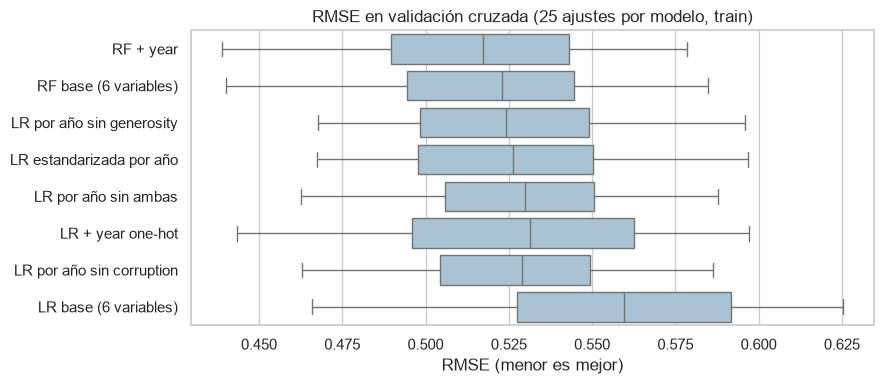

In [19]:
orden = resumen.index.tolist()
largo_cv = pd.concat([d.assign(modelo=n) for n, d in resultados_cv.items()])
fig, ax = plt.subplots(figsize=(9, 4))
sns.boxplot(data=largo_cv, y="modelo", x="rmse", order=orden, color="#a1c4dd", ax=ax)
ax.set_title("RMSE en validación cruzada (25 ajustes por modelo, train)")
ax.set_xlabel("RMSE (menor es mejor)")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

### 5.2 Comparaciones directas
La tabla anterior compara todo contra la LR base. Para decidir hacen falta comparaciones entre pares concretos
(mismas 25 particiones, prueba t corregida). Se agregan las variantes con `year` one-hot sin las variables débiles.

In [20]:
extra = {
    "LR + year sin generosity": lineal(sin_gen, "onehot"),
    "LR + year sin corruption": lineal(sin_cor, "onehot"),
    "LR + year sin ambas": lineal(sin_ambas, "onehot"),
}
for nombre, modelo in extra.items():
    r = cross_validate(modelo, X_train, y_train, cv=cv, scoring=metricas)
    resultados_cv[nombre] = pd.DataFrame({"rmse": -r["test_rmse"], "mae": -r["test_mae"], "r2": r["test_r2"]})

pares = [
    ("LR estandarizada por año", "LR + year one-hot", "¿Estandarizar por año mejora al one-hot?"),
    ("LR + year sin generosity", "LR + year one-hot", "¿Quitar generosity empeora?"),
    ("LR + year sin corruption", "LR + year one-hot", "¿Quitar corruption empeora?"),
    ("LR + year sin ambas", "LR + year one-hot", "¿Quitar las dos empeora?"),
    ("RF + year", "LR + year one-hot", "¿Random Forest mejora a la lineal con año?"),
    ("RF + year", "RF base (6 variables)", "¿El año ayuda al Random Forest?"),
]
filas = []
for a, b, pregunta in pares:
    dif, t, p = t_corregida(resultados_cv[a]["rmse"], resultados_cv[b]["rmse"], n_fit, n_val)
    filas.append({"pregunta": pregunta, "modelo_A": a, "modelo_B": b,
                  "RMSE_A": resultados_cv[a]["rmse"].mean(), "RMSE_B": resultados_cv[b]["rmse"].mean(),
                  "dif_A_menos_B": dif, "p_valor": p})
pd.DataFrame(filas).set_index("pregunta")

,modelo_A,modelo_B,RMSE_A,RMSE_B,dif_A_menos_B,p_valor
pregunta,,,,,,
¿Estandarizar por año mejora al one-hot?,LR estandarizada por año,LR + year one-hot,0.529,0.530,-7.708e-04,0.890
¿Quitar generosity empeora?,LR + year sin generosity,LR + year one-hot,0.529,0.530,-6.835e-04,0.530
¿Quitar corruption empeora?,LR + year sin corruption,LR + year one-hot,0.531,0.530,1.053e-03,0.812
¿Quitar las dos empeora?,LR + year sin ambas,LR + year one-hot,0.531,0.530,9.811e-04,0.837
¿Random Forest mejora a la lineal con año?,RF + year,LR + year one-hot,0.515,0.530,-1.473e-02,0.320
¿El año ayuda al Random Forest?,RF + year,RF base (6 variables),0.515,0.519,-3.761e-03,0.039


### 5.3 Coeficientes de la regresión lineal con año (ajustada sobre todo el train)
Con las variables estandarizadas los coeficientes son comparables: indican cuántos puntos de felicidad cambia
el puntaje por cada desviación estándar de la variable, manteniendo las demás y el año fijos.
Los errores estándar y p-valores son los de mínimos cuadrados ordinarios (MCO); el intervalo de confianza
del 95 % se estima además con *bootstrap* (1 000 remuestreos), que no supone normalidad de los residuos.

In [21]:
def ols_tabla(X, y):
    """Coeficientes MCO con error estándar, t y p-valor (X sin constante; se agrega aquí)."""
    Xc = np.column_stack([np.ones(len(X)), X])
    beta, *_ = np.linalg.lstsq(Xc, y, rcond=None)
    resid = y - Xc @ beta
    gl = len(y) - Xc.shape[1]
    sigma2 = resid @ resid / gl
    se = np.sqrt(np.diag(sigma2 * np.linalg.inv(Xc.T @ Xc)))
    t = beta / se
    return beta, se, t, 2 * stats.t.sf(np.abs(t), gl)


modelo_lr = lineal(FEATURES, "onehot").fit(X_train, y_train)
prep = modelo_lr.named_steps["prep"]
Xt = prep.transform(X_train)
nombres = [n.split("__")[1] for n in prep.get_feature_names_out()]
beta, se, t, p = ols_tabla(Xt, y_train.to_numpy())

rng = np.random.default_rng(RANDOM_STATE)
boot = []
for _ in range(1000):
    idx = rng.integers(0, len(Xt), len(Xt))
    boot.append(LinearRegression().fit(Xt[idx], y_train.to_numpy()[idx]).coef_)
boot = np.array(boot)

coeficientes = pd.DataFrame({
    "coef": beta[1:], "error_std": se[1:], "t": t[1:], "p_valor": p[1:],
    "boot_ic95_inf": np.percentile(boot, 2.5, axis=0), "boot_ic95_sup": np.percentile(boot, 97.5, axis=0),
}, index=nombres)
coeficientes

,coef,error_std,t,p_valor,boot_ic95_inf,boot_ic95_sup
gdp,0.339,0.045,7.466,3.362e-13,0.242,0.432
family,0.379,0.037,10.131,3.455e-22,0.305,0.449
health,0.233,0.042,5.599,3.449e-08,0.150,0.324
freedom,0.253,0.028,9.006,3.730e-18,0.199,0.307
generosity,0.019,0.026,0.754,4.511e-01,-0.032,0.075
corruption,0.071,0.026,2.693,7.305e-03,0.005,0.132
year_2016,0.354,0.078,4.537,7.035e-06,0.196,0.512
year_2017,-0.210,0.079,-2.663,7.968e-03,-0.350,-0.054
year_2018,-0.270,0.076,-3.564,3.982e-04,-0.424,-0.123
year_2019,-0.276,0.075,-3.663,2.741e-04,-0.437,-0.131


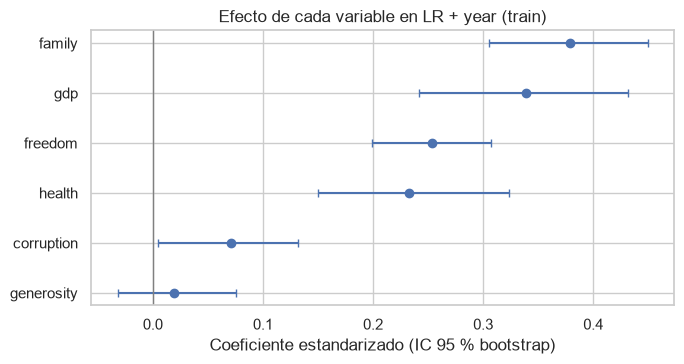

In [22]:
fig, ax = plt.subplots(figsize=(7, 3.8))
orden_c = coeficientes.loc[FEATURES, "coef"].sort_values().index
c = coeficientes.loc[orden_c]
ax.errorbar(c["coef"], range(len(c)), xerr=[c["coef"] - c["boot_ic95_inf"], c["boot_ic95_sup"] - c["coef"]],
            fmt="o", color="#4c72b0", capsize=3)
ax.axvline(0, color="grey", lw=1)
ax.set_yticks(range(len(c)), c.index)
ax.set_xlabel("Coeficiente estandarizado (IC 95 % bootstrap)")
ax.set_title("Efecto de cada variable en LR + year (train)")
plt.tight_layout()
plt.show()

### 5.4 Residuos del modelo lineal con año
Se revisa si los errores tienen algún patrón (por ejemplo, curvatura) que justifique un modelo no lineal.
Se usan predicciones fuera de *fold* (cada fila predicha por un modelo que no la vio).

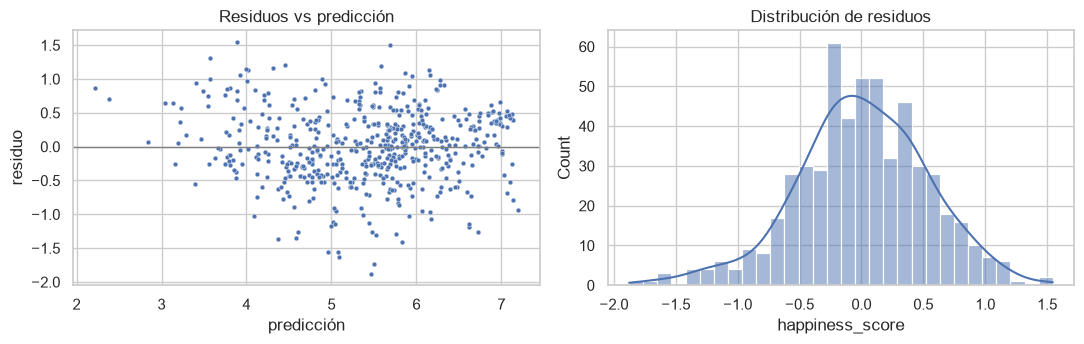

media_residuo                 0.001
desv_residuo                  0.533
spearman_pred_vs_abs_resid   -0.076
spearman_p                    0.074
dtype: float64

In [23]:
from sklearn.model_selection import KFold, cross_val_predict

pred_oof = cross_val_predict(lineal(FEATURES, "onehot"), X_train, y_train,
                             cv=KFold(5, shuffle=True, random_state=RANDOM_STATE))
resid = y_train - pred_oof
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
sns.scatterplot(x=pred_oof, y=resid, s=12, ax=axes[0], color="#4c72b0")
axes[0].axhline(0, color="grey", lw=1)
axes[0].set(xlabel="predicción", ylabel="residuo", title="Residuos vs predicción")
sns.histplot(resid, bins=30, kde=True, ax=axes[1], color="#4c72b0")
axes[1].set_title("Distribución de residuos")
plt.tight_layout()
plt.show()

pd.Series({"media_residuo": resid.mean(), "desv_residuo": resid.std(),
           "spearman_pred_vs_abs_resid": stats.spearmanr(pred_oof, resid.abs()).statistic,
           "spearman_p": stats.spearmanr(pred_oof, resid.abs()).pvalue}).round(4)

## 6. Conclusiones y propuesta de features

| # | Hallazgo | Evidencia |
|---|----------|-----------|
| 1 | El puntaje es estable entre años | ANOVA p = 0.67, Kruskal-Wallis p = 0.69, Levene p = 0.88 (§2.2) |
| 2 | Las variables explicativas cambian de escala entre reportes; el caso fuerte es `family` | Kruskal-Wallis ε² = 0.29 (efecto grande) en `family`; pequeño en `health`, `generosity`, `freedom`, `gdp` (§3.2) |
| 3 | Es un cambio de metodología, no de los países: casi todos se mueven en la misma dirección a la vez | `family` 2015→2016: baja el 100 % de los países; 2016→2017: sube el 100 %. `gdp` 2017→2018: baja el 97 %. `health` 2018→2019: sube el 99 % (§3.3) |
| 4 | Mezclar años sin corregir debilita la relación de `family` con el puntaje | Correlación dentro de cada año ≈ 0.75; agrupada 0.63 (§4.3) |
| 5 | No hay colinealidad preocupante | VIF máximo 2.98 (`gdp`) (§4.4) |
| 6 | Usar el año mejora el modelo lineal de forma significativa | RMSE 0.554 → 0.530 (−4.4 %), p = 0.023 con prueba t corregida (§5.1) |
| 7 | One-hot del año y estandarización por año son equivalentes | p = 0.89 (§5.2) |
| 8 | `generosity` no aporta | Coeficiente 0.019, p = 0.45, IC 95 % bootstrap [−0.03, 0.08]; quitarla no cambia el RMSE (p = 0.53) |
| 9 | `corruption` aporta poco pero de forma consistente | Coeficiente 0.071, p = 0.007, IC 95 % bootstrap [0.005, 0.13]; quitarla no cambia el RMSE de forma medible (p = 0.81) |
| 10 | Random Forest no mejora de forma significativa a la lineal con año | RMSE 0.515 vs 0.530 (−2.8 %), p = 0.32 (§5.2) |
| 11 | Los residuos de la lineal con año no muestran patrón | Media ≈ 0; sin relación entre predicción y tamaño del error (Spearman p = 0.07) (§5.4) |

**Propuesta para `model_training.ipynb`** (pendiente de confirmar):
- **Modelo:** regresión lineal. Random Forest no es significativamente mejor, es menos interpretable y más pesado; el taller pide un modelo simple.
- **Año:** `year` entra con one-hot (más simple que una clase propia y equivalente en desempeño). `year` viene en el evento y no deriva del puntaje, así que no hay fuga. Un año que no se vio en el entrenamiento se trata como el año base (2015).
- **Variables:** `gdp`, `family`, `health`, `freedom` y `corruption`, estandarizadas dentro del `Pipeline`. Se propone **quitar `generosity`**: no es significativa y no mejora la predicción.
- **Fuga del target:** ninguna variable deriva del puntaje (los rankings y `Dystopia Residual` ya se descartaron en la limpieza).